1.   **Analysis of News Articles**
2.   **Anna Korostelyova**
3.   **Context**:
    Analysis of News Articles dataset contains information on titles and category of an article. During this assignment I practiced Supervised Lerning (Tree-based method - Random forests), hyperparametr tuning, reported my model performance, and Unsupervised learning (Principle Component Analysis and KMeans Clustering). Main task was to aplly knowledge about Unsupervised learning and build the model which is going to predict whether an article belongs to the group of 'world' theme articles.
4.   **Findings**
 *   In Task 1, we just witnessed that PCA in fact helps to retain most of information. Overall, from graphs it was hard do detect groups, but still - we see that articles of the same category were pooled
  *   In Task 2, after defining clusters with KMean Clustering, we saw a little overlap of two categories in one cluster. It was a mix sci/tech and business, which could make sence because businesses nowerdays are highly related with technology (either selling it or using).
   *   In Task 3, PCA was included into normal flow of model  building. What is new - I used RandomizedSearchCV and n_iter parameter to decrease the time which is needed to execute code. Overall, model is good at predicting (at least better than model from previous homework - maybe it is due specifics of a task but still a little progress)

# Dataset Prep

This notebook loads [this dataset](https://huggingface.co/datasets/sh0416/ag_news), samples 40k rows, transforms the `label` column, extracts embeddings of the `title` column and saves the new dataset.

In [ ]:
import pandas as pd
from sentence_transformers import SentenceTransformer


In [ ]:
df = pd.read_json("https://huggingface.co/datasets/sh0416/ag_news/resolve/main/train.jsonl", lines=True)


In [ ]:
df.sample(10)

,label,title,description
37749,3,Gates Tops Forbes List of Richest in US -- Again,The Nasdaq may be well off its highs of the do...
80999,4,Beauty creams then and now - the same,Archeologists found a small container with a w...
73943,1,Iraqi Rebels Threaten Japanese Hostage,A video posted Tuesday on a militant Islamic W...
96762,2,More Pain In Spain,Spains midweek international friendly victory ...
112754,2,Brazelton wins Tony Conigliaro Award,"Boston, MA (Sports Network) - Tampa Bay Devil ..."
69311,4,Synchrotron puts city into national spotlight,"With a flick of a giant switch, Canada #39;s b..."
48940,4,Genome Model Applied to Software,Open-source developers attempting to reverse-e...
1500,4,Microsoft delays SP2 auto update,Microsoft is delaying distribution of Windows ...
71142,3,IBM unveils challenge to EMC,"For the second time in two weeks, IBM Corp. wi..."
87234,2,ESPN: Fiesta Bowl turning point for freshman C...,In the week leading up to the 2003 Fiesta Bowl...


In [ ]:
df_sample = df.groupby('label')[["label", "title"]].apply(lambda x: x.sample(n=5000)).reset_index(drop=True)


In [ ]:
df_sample.sample(10)

,label,title
8006,2,Chelsea display championship class
5942,2,Sightseek goes out in smashing style
6753,2,New model Safin rediscovers hot shots
12642,3,DreamWorks IPO Surges
12960,3,"Japan #39;s Nikkei Falls; Nintendo, Sharp Drop..."
13624,3,Insurance Scandal
14539,3,McGregor: Back In The US To Head Broadcom
1241,1,Fallujah Insurgents Fight US Marines for Secon...
2685,1,"2 Americans, Briton seized in Iraq Civilian fo..."
8960,2,Teammates go to bat for the ace after loss


In [ ]:
df_sample = df_sample.rename(columns={'label': 'category'})
label_map = {1: 'world', 2: 'sports', 3: 'business', 4: 'sci/tech'}
df_sample['category'] = df_sample['category'].map(label_map)


In [ ]:
df_sample.sample(10)

,category,title
1674,world,Kazakhs vote in general election
18514,sci/tech,Photo 7 of 8: Global gamers clash for cash
4787,world,EU Set to Announce Funding for AU Darfur Force...
19490,sci/tech,Limited EyeToy Support in GT4
3523,world,Housing report slams US and Sudan
4754,world,Report: Man in Jakarta bombing arrested
13741,business,Schering-Plough lands quartet of Bayer drugs
4621,world,"Sudan, UN Sign Deal on #39;Refugees Return #39;"
2467,world,Pakistan Tests Medium-Range Nuclear-Capable Mi...
2736,world,"Hijackers grab Greek bus passengers, demand 1 ..."


In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df_sample['title'].tolist())

In [ ]:
df_sample["title_embedding"] = list(embeddings)

In [ ]:
df_sample.sample(10)

,category,title,title_embedding
10461,business,"Biogen, Elan merger rumors persist","[-0.07056124, -0.032312308, 0.03811024, -0.086..."
9625,sports,Throwing the book at final season effort of Ja...,"[-0.057309736, 0.009327473, -0.0070327516, 0.0..."
15202,sci/tech,Cisco to sell high-end routers with Fujitsu,"[-0.08538779, -0.05361665, -0.0539137, -0.0014..."
1545,world,Ailing Palestinian leader Yasser Arafat arrive...,"[0.048706, -0.0214554, 0.03651936, 0.004242071..."
9401,sports,"Clarett, Owens best seen but not heard","[-0.031350907, -0.028990882, -0.05689026, -0.0..."
18795,sci/tech,New Firm Launches Web Services-Based Collabora...,"[0.004220313, -0.10870984, -0.10829737, -0.107..."
17594,sci/tech,RealNetworks Sells Three Million Songs Through...,"[-0.056061886, -0.13048765, -0.09893924, -0.00..."
15053,sci/tech,Macromedia Bolsters Flex with New Development ...,"[0.011694159, -0.08901507, 0.024286227, -0.007..."
3335,world,Bush wants Annan to stay,"[-0.013090821, -0.033569656, 0.06646863, 0.104..."
7828,sports,Jefferson pledges to stay hungry,"[-0.013600956, 0.003526485, 0.0049882573, 0.03..."


In [ ]:
df_sample.to_csv('ag_news.csv', index=False)

# PCA

In [ ]:
emb_df = pd.DataFrame(embeddings)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
embeddings_pca = pca.fit_transform(emb_df)

In [ ]:
df_sample['pc1'] = embeddings_pca[:, 0]
df_sample['pc2'] = embeddings_pca[:, 1]
df_sample['pc3'] = embeddings_pca[:, 2]

df_sample.head()

,category,title,title_embedding,pc1,pc2,pc3
0,world,U.N. Won't Train Judges for Iraq Tribunal (AP),"[0.019675672, -0.00047962807, -0.073143594, -0...",-0.114536,-0.303726,-0.018922
1,world,Ten killed in fresh Assam attack,"[-0.029687265, 0.030046288, -0.002561501, -0.0...",-0.169604,-0.257769,-0.047785
2,world,Bill Clinton Heart Surgery Successful,"[0.029999122, 0.0690365, -0.012782543, -0.0164...",-0.046234,0.018036,0.008620
3,world,7 US Soldiers Killed,"[-0.020315498, -0.0737135, 0.000982611, 0.0100...",-0.201749,-0.263425,0.005268
4,world,UN Rights Officials Tell Security Council Inte...,"[-0.08757941, 0.080157354, -0.035182443, 0.001...",-0.058781,-0.440922,-0.113707


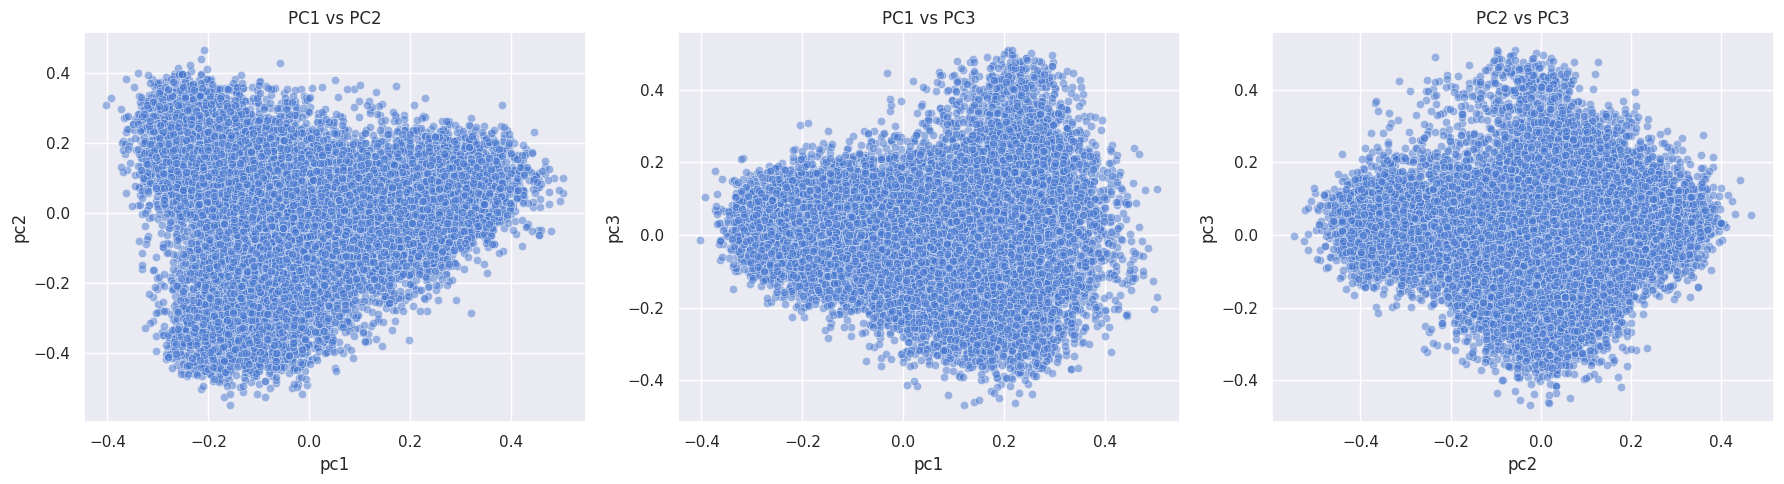

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_sample, x='pc1', y='pc2', alpha=0.5, ax=axes[0])
axes[0].set_title('PC1 vs PC2')

sns.scatterplot(data=df_sample, x='pc1', y='pc3', alpha=0.5, ax=axes[1])
axes[1].set_title('PC1 vs PC3')

sns.scatterplot(data=df_sample, x='pc2', y='pc3', alpha=0.5, ax=axes[2])
axes[2].set_title('PC2 vs PC3')

plt.tight_layout()
plt.show()

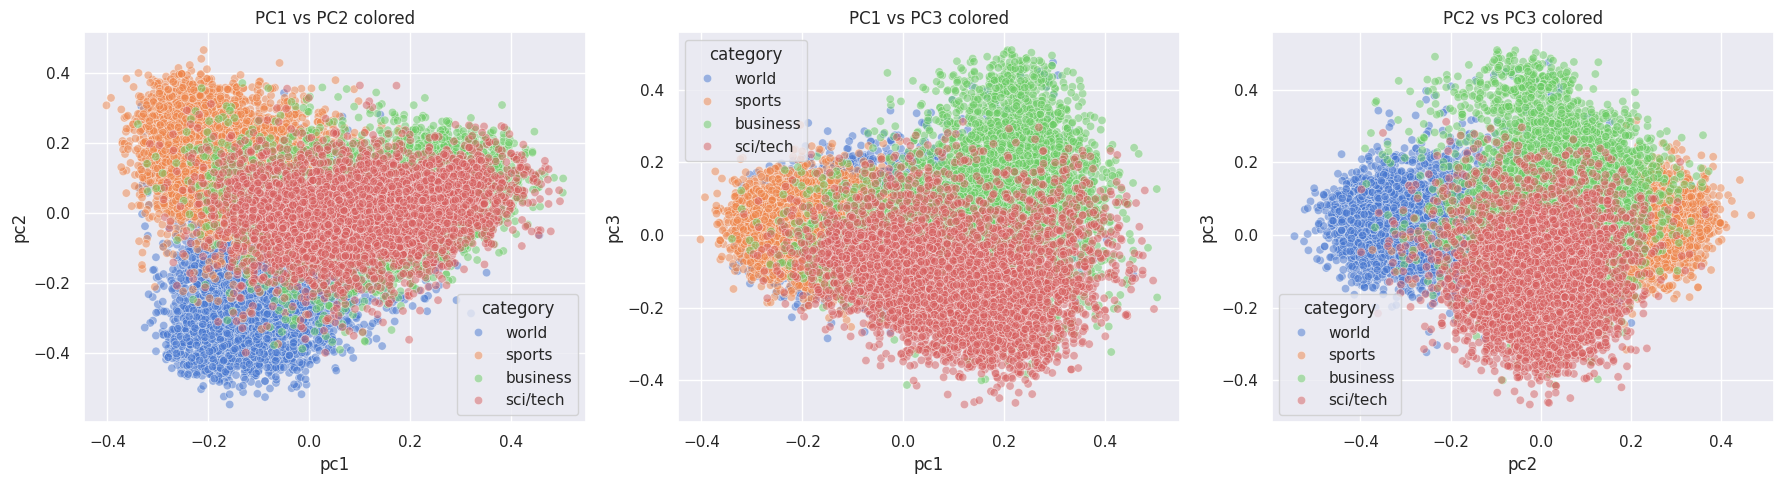

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_sample, x='pc1', y='pc2', hue='category', alpha=0.5, ax=axes[0])
axes[0].set_title('PC1 vs PC2 colored')

sns.scatterplot(data=df_sample, x='pc1', y='pc3', hue='category', alpha=0.5, ax=axes[1])
axes[1].set_title('PC1 vs PC3 colored')

sns.scatterplot(data=df_sample, x='pc2', y='pc3', hue='category', alpha=0.5, ax=axes[2])
axes[2].set_title('PC2 vs PC3 colored')

plt.tight_layout()
plt.show()


It's not really clear, whether catgories are overlaping, therefore, I'll plot graph with 3 dimenstions

In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df_sample,
    x='pc1', y='pc2', z='pc3',
    hover_data=['title'],
    title='3D PCA',
    opacity=0.7
)

fig.update_layout(
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    )
)

fig.show()

In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df_sample,
    x='pc1', y='pc2', z='pc3',
    color='category',
    hover_data=['title'],
    title='3D PCA - colored',
    opacity=0.7
)

fig.update_layout(
    legend=dict(title='Category'),
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    )
)

fig.show()


Overall, if we color the graphs, we can distinguish categories (although, business and sci-tech seem to be overlaping).

But if not to color the plot - we just see from the first glance homogenous cloud. So, by using only eyes we cannot detect the categories.

Also, from the coloring we can see that articles that have same category are located near each other - good sign:)

# Choosing n_cluster

<Axes: xlabel='k', ylabel='inertia'>

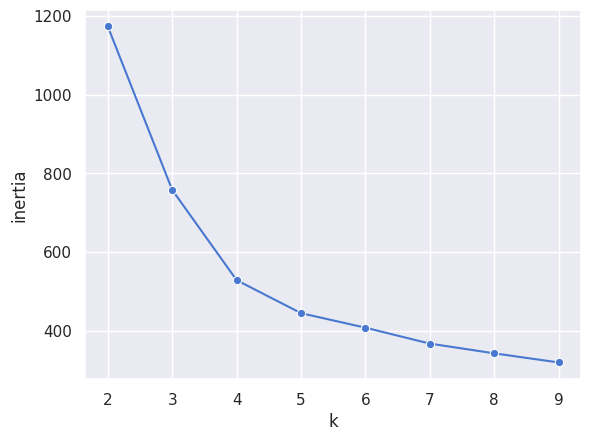

In [ ]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 10)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_sample[['pc1', 'pc2', 'pc3']])
    inertias.append(kmeans.inertia_)

elbow_data = pd.DataFrame({'k': k_values, 'inertia': inertias})
sns.lineplot(x='k', y='inertia', data=elbow_data, marker='o')

After 4 clusters, decrease in total whithin cluster sum of squares (inertia) starts to decrease by approximately the same amount => using elbow method, I choose n_clusters=4

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4)
clusters = kmeans.fit_predict(df_sample[['pc1', 'pc2', 'pc3']])

df_sample['cluster'] = clusters

df_sample.groupby(['cluster', 'category']).size()

cluster  category
0        business     430
         sci/tech     442
         sports      4533
         world        485
1        business    3042
         sci/tech     464
         sports        94
         world        286
2        business     244
         sci/tech     371
         sports       171
         world       3882
3        business    1284
         sci/tech    3723
         sports       202
         world        347
dtype: int64

So, based on thet we can see that Cluster 0 is more related with sci/tech but! it is a bit mixed with business (which by the way was seen from the colored plots). Cluster 1 - sports, Cluster 2 - world, Cluster 3 - business

# PCA with 3 principal components

In [ ]:
from sklearn.model_selection import train_test_split

y = df_sample['category'] == 'world'
X = emb_df

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA

model = Pipeline([
    ('pca', PCA(n_components=10)),
    ('rf', RandomForestClassifier(random_state=42))
])

model.fit(X_train, y_train)

Pipeline(steps=[('pca', PCA(n_components=10)),
                ('rf', RandomForestClassifier(random_state=42))])

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    'rf__n_estimators': [100, 200],
    'rf__max_depth': range(10, 21),
    'rf__class_weight': ['balanced', None],
    'rf__min_samples_split': range(2, 10),
}

rf_grid_search = RandomizedSearchCV(model, rf_param_grid, n_iter=30, cv=5, scoring='roc_auc', n_jobs=-1)
rf_grid_search.fit(X_train, y_train)

print(rf_grid_search.best_params_)

{'rf__n_estimators': 200, 'rf__min_samples_split': 2, 'rf__max_depth': 11, 'rf__class_weight': 'balanced'}


I've used RandomizedSearchCV in order to decrease time for executing the code:)

In [ ]:
from sklearn.metrics import classification_report

y_pred = rf_grid_search.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.94      0.95      0.94      3031
        True       0.84      0.81      0.82       969

    accuracy                           0.92      4000
   macro avg       0.89      0.88      0.88      4000
weighted avg       0.91      0.92      0.92      4000

